In [1]:
import pandas as pd
import numpy as np
from hpelm import ELM
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# Load small subset only
df_normal = pd.read_csv("df_normal_processed.csv", nrows=5000)
df_ddos   = pd.read_csv("df_ddos_processed.csv", nrows=5000)

# Labels
df_normal['label'] = 0
df_ddos['label'] = 1

# Combine
df = pd.concat([df_normal, df_ddos], ignore_index=True)

print(df.shape)

(10000, 776)


In [9]:
# Separate features and labels
X = df.drop(columns=['label'])
y = df['label']

# Convert to numpy
X = X.values.astype(np.float32)
y = y.values.astype(np.float32)

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create ELM model
elm = ELM(
    X_scaled.shape[1],   # input neurons
    2                    # output classes
)

# Add hidden layer
elm.add_neurons(256, 'sigm')

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [11]:
# One-hot for training
y_train_onehot = np.zeros((len(y_train), 2))
y_train_onehot[np.arange(len(y_train)), y_train.astype(int)] = 1

elm.train(X_train, y_train_onehot, 'c')

In [12]:
y_pred = elm.predict(X_test)
y_pred_binary = np.argmax(y_pred, axis=1)

print(confusion_matrix(y_test, y_pred_binary))
print(classification_report(y_test, y_pred_binary))

[[1495    5]
 [   5 1495]]
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1500
         1.0       1.00      1.00      1.00      1500

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



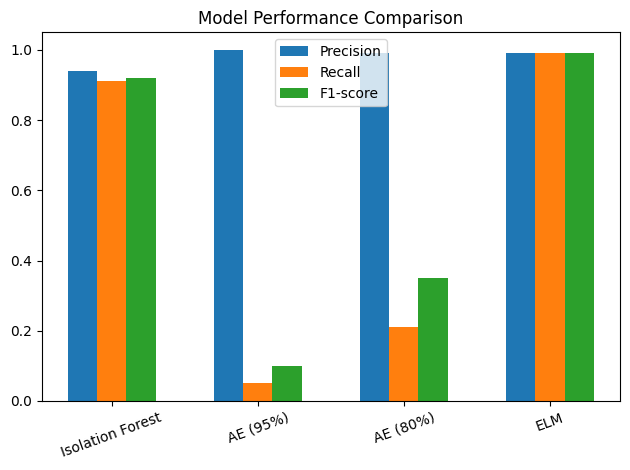

In [13]:
import matplotlib.pyplot as plt

models = ['Isolation Forest', 'AE (95%)', 'AE (80%)', 'ELM']
precision = [0.94, 1.00, 0.99, 0.99]
recall = [0.91, 0.05, 0.21, 0.99]
f1 = [0.92, 0.10, 0.35, 0.99]

x = range(len(models))

plt.figure()
plt.bar(x, precision, width=0.2, label='Precision')
plt.bar([i+0.2 for i in x], recall, width=0.2, label='Recall')
plt.bar([i+0.4 for i in x], f1, width=0.2, label='F1-score')

plt.xticks([i+0.2 for i in x], models, rotation=20)
plt.legend()
plt.title("Model Performance Comparison")

plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()